In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx

# ============================================================
# FILES
# ============================================================

JHARKHAND_FILE = "../data/polygons/jharkhand.geojson"
ODISHA_FILE    = "../data/polygons/odisha.geojson"

HIGHLIGHT_DISTRICT =  None



In [2]:
plt.rcParams['figure.figsize'] = (15, 10)
plt.rcParams['figure.dpi'] = 300

Invalid geometries before repair: 3
Invalid geometries after repair: 0


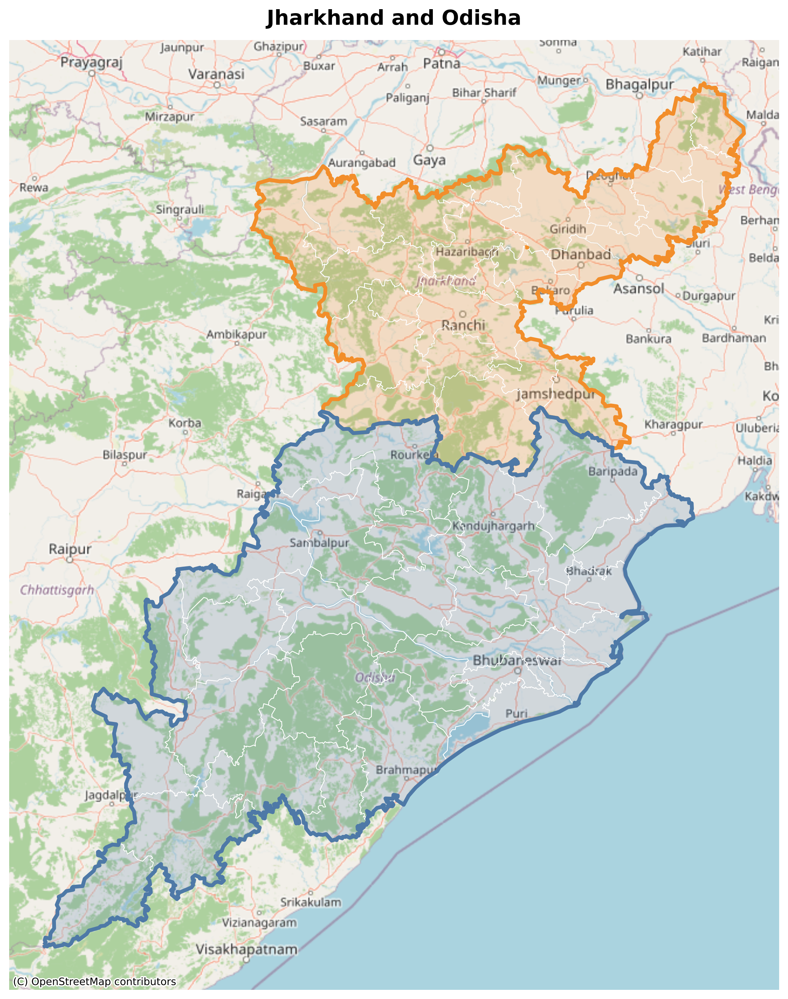

In [3]:

# ============================================================
# LOAD DATA
# ============================================================

jh = gpd.read_file(JHARKHAND_FILE)
od = gpd.read_file(ODISHA_FILE)

# Same CRS
if jh.crs != od.crs:
    od = od.to_crs(jh.crs)

admin = gpd.GeoDataFrame(
    pd.concat([jh, od], ignore_index=True),
    crs=jh.crs
)


# ============================================================
# REPAIR INVALID GEOMETRIES
# ============================================================

print("Invalid geometries before repair:", (~admin.geometry.is_valid).sum())

admin["geometry"] = admin.geometry.make_valid()

# Remove empty/null geometries if any
admin = admin[
    admin.geometry.notna() &
    ~admin.geometry.is_empty
].copy()

print("Invalid geometries after repair:", (~admin.geometry.is_valid).sum())


# ============================================================
# PROJECT FOR WEB BASEMAP
# ============================================================

admin = admin.to_crs(epsg=3857)

jh = admin[
    admin["st_nm"].astype(str).str.strip().str.lower()
    == "jharkhand"
].copy()

od = admin[
    admin["st_nm"].astype(str).str.strip().str.lower()
    == "odisha"
].copy()


def draw_map(data=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 11))
        standalone = True
    else:
        fig = ax.figure
        standalone = False

    jh.plot(ax=ax, facecolor="#F28E2B", edgecolor="none", alpha=0.20, zorder=2)
    od.plot(ax=ax, facecolor="#4E79A7", edgecolor="none", alpha=0.20, zorder=2)
    admin.boundary.plot(ax=ax, color="white", linewidth=0.6, alpha=0.9, zorder=3)
    jh.dissolve().boundary.plot(ax=ax, color="#F28E2B", linewidth=3.0, zorder=4)
    od.dissolve().boundary.plot(ax=ax, color="#4E79A7", linewidth=3.0, zorder=4)

    if HIGHLIGHT_DISTRICT is not None:
        selected = admin[
            admin["district"].astype(str).str.strip().str.lower()
            == HIGHLIGHT_DISTRICT.lower()
        ]
        if not selected.empty:
            selected.plot(ax=ax, facecolor="#FFFF00", edgecolor="#D62728",
                          linewidth=2.5, alpha=0.60, zorder=5)
            print(f"Highlighted: {HIGHLIGHT_DISTRICT} ({selected.iloc[0]['st_nm']})")
        else:
            print(f"District not found: {HIGHLIGHT_DISTRICT}")

    xmin, ymin, xmax, ymax = admin.total_bounds
    dx, dy = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
    ax.set_xlim(xmin - dx, xmax + dx)
    ax.set_ylim(ymin - dy, ymax + dy)

    ctx.add_basemap(
        ax,
        source=ctx.providers.OpenStreetMap.Mapnik,
        headers={"User-Agent": "GroundwaterData/1.0"},
        zorder=1,
    )

    if data is not None and not data.empty:
        data.to_crs(admin.crs).plot(
            ax=ax, color="red", markersize=8, zorder=6
        )

    ax.set_title("Jharkhand and Odisha", fontsize=16, fontweight="bold", pad=12)
    ax.set_axis_off()
    if standalone:
        fig.tight_layout()
    return fig, ax


# Clean map
fig, ax = draw_map()
plt.show()



In [4]:
locations = pd.read_csv("../data/station_locations.csv", dtype={"Station": "string"})
points = gpd.GeoDataFrame(
    locations,
    geometry=gpd.points_from_xy(locations.Longitude, locations.Latitude),
    crs="EPSG:4326",  # Assumes source coordinates are WGS84.
)
len(points[['Category']].drop_duplicates())


12

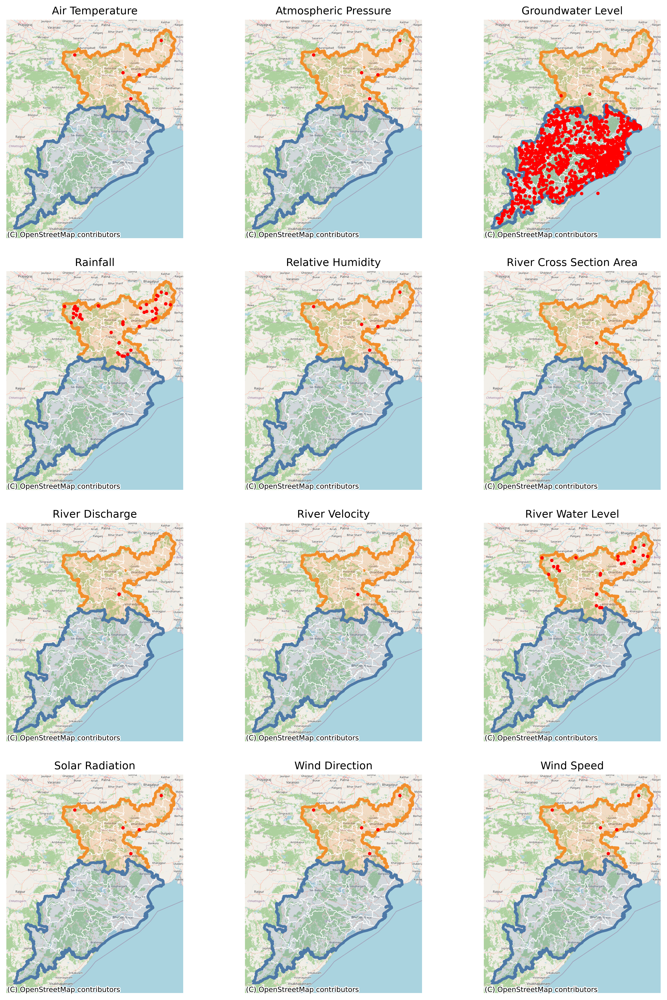

In [5]:
categories = sorted(points['Category'].dropna().unique())
if not categories:
    raise ValueError('No categories found in points')

columns = 3
rows = (len(categories) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(columns * 4, rows * 4), squeeze=False)

for ax_current, category in zip(axes.flat, categories):
    selected = points[points['Category'] == category]
    draw_map(selected, ax=ax_current)
    ax_current.set_title(category.replace('_', ' ').title())

for ax_current in axes.flat[len(categories):]:
    ax_current.set_visible(False)

fig.tight_layout()
plt.show()

In [6]:
from pathlib import Path
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
STATION = '25M03BW008'
AGENCY = 'Odisha GW'
LATITUDE, LONGITUDE = 20.4046, 85.0413
START = pd.Timestamp('2021-01-01')
parts = []
for data_type, pattern in [('manual_quarterly', 'gwl_manual_quarterly*.csv'),
                           ('telemetry_6_hourly', 'gwl_tel_6_hourly*.csv')]:
    files = sorted((ROOT / 'data' / 'odisha').glob(pattern))
    if not files:
        raise FileNotFoundError(f'No {data_type} files found')
    for path in files:
        header = pd.read_csv(path, nrows=0, encoding='utf-8-sig').columns
        measurements = [name for name in header if name.startswith('Groundwater Level')]
        if len(measurements) != 1:
            raise ValueError(f'{path.name}: expected one groundwater-level column')
        level_column = measurements[0]
        columns = ['Agency', 'Station', 'State', 'District', 'Latitude', 'Longitude',
                   'Data Acquisition Time', level_column]
        with pd.read_csv(path, usecols=columns, dtype='string', keep_default_na=False,
                         encoding='utf-8-sig', chunksize=25_000) as reader:
            for chunk in reader:
                selected = chunk[(chunk.Agency == AGENCY) & (chunk.Station == STATION)].copy()
                if selected.empty:
                    continue
                same_location = (pd.to_numeric(selected.Latitude, errors='raise').eq(LATITUDE)
                                 & pd.to_numeric(selected.Longitude, errors='raise').eq(LONGITUDE))
                selected = selected.loc[same_location].copy()
                selected['date'] = pd.to_datetime(selected['Data Acquisition Time'],
                                                  format='%d-%m-%Y %H:%M', errors='raise')
                selected = selected[selected.date >= START].copy()
                if selected.empty:
                    continue
                selected['reported_value'] = selected[level_column]
                selected['level_m'] = pd.to_numeric(selected.reported_value, errors='coerce')
                selected['data_type'] = data_type
                selected['source_file'] = path.name
                selected['source_row'] = selected.index + 2
                parts.append(selected[['Agency', 'Station', 'State', 'District', 'Latitude',
                                       'Longitude', 'date', 'reported_value', 'level_m',
                                       'data_type', 'source_file', 'source_row']])
if not parts:
    raise ValueError(f'No readings found for {STATION} at the selected location/date window')
station_readings = pd.concat(parts, ignore_index=True).sort_values('date')
display(station_readings.groupby('data_type').agg(
    records=('date', 'size'), first_date=('date', 'min'), last_date=('date', 'max'),
    minimum_reported_m=('level_m', 'min'), maximum_reported_m=('level_m', 'max')))
invalid_values = station_readings.level_m.isna().sum()
print(f'{invalid_values} nonnumeric/missing readings retained in the table but excluded from the plot.')
print('Raw signs are preserved. Do not interpret differences until measurement datum/sign conventions are confirmed.')

FileNotFoundError: No manual_quarterly files found

## Shared-station time series: 25M03BW008, Nayagarh

The cell above streams the original files and retains only this agency/station at **20.4046 N, 85.0413 E**, from 2021 onward. It does not load the full telemetry archive. Manual data are quarterly; telemetry is declared six-hourly, not hourly. Actual sampling gaps are not filled.

The plots below show raw readings over the full selected period and a zoom to the intersection of the two series' date ranges. An overlapping date range does not establish contemporaneous paired measurements. Manual readings are positive and telemetry negative; no sign reversal, offset, resampling or averaging is applied. Historical manual values include `-999`, outside the selected window, whose meaning needs source metadata. `station_readings` retains original value strings and source file/row references.

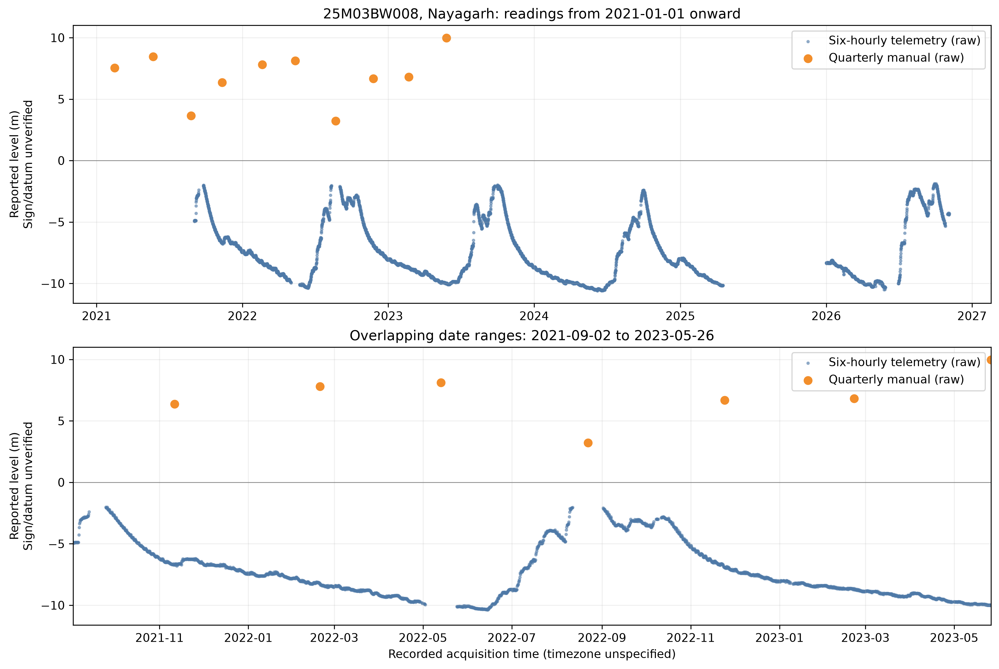

In [ ]:
series = {}
for data_type in ['manual_quarterly', 'telemetry_6_hourly']:
    series[data_type] = station_readings[
        (station_readings.data_type == data_type) & station_readings.level_m.notna()]
    if series[data_type].empty:
        raise ValueError(f'No plottable {data_type} readings for the selected station')
overlap_start = max(frame.date.min() for frame in series.values())
overlap_end = min(frame.date.max() for frame in series.values())
if overlap_start >= overlap_end:
    raise ValueError('The selected series do not have an overlapping date range')

fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout='constrained')
styles = [('telemetry_6_hourly', '#4E79A7', 4, 0.5, 'Six-hourly telemetry (raw)'),
          ('manual_quarterly', '#F28E2B', 45, 1.0, 'Quarterly manual (raw)')]
for ax in axes:
    for data_type, color, size, alpha, label in styles:
        frame = series[data_type]
        ax.scatter(frame.date, frame.level_m, s=size, alpha=alpha,
                   color=color, label=label)
    ax.axhline(0, color='grey', linewidth=0.6)
    ax.set_ylabel('Reported level (m)\nSign/datum unverified')
    ax.grid(alpha=0.2)
    ax.legend(loc='upper right')
axes[0].set_title(f'{STATION}, Nayagarh: readings from {START.date()} onward')
axes[1].set_xlim(overlap_start, overlap_end)
axes[1].set_title(f'Overlapping date ranges: {overlap_start.date()} to {overlap_end.date()}')
axes[1].set_xlabel('Recorded acquisition time (timezone unspecified)')
plt.show()